# DisCO: Three Fixes, With the Code Behind Them

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/samaksh97/grpo-then-and-now/blob/main/notebook/disco_three_fixes.ipynb)

This notebook turns the slide deck [`slides/disco_intro.html`](../slides/disco_intro.html) into a guided lab. The deck develops the argument; here we check each claim with a small experiment, interpret the result, and then vary the setup. Each section points back to the relevant slides so you can keep the explanation and the code side by side.

**How to use this notebook** (about 45 minutes, CPU only, runs in about 3 seconds). Sections 1–3 each take about 10 minutes; Section 4 combines them. **Fast path:** run each section's *Predict*, *Inspect* and *Explain* cells and skip the *Optional exploration* cells on a first pass. Prerequisites: the GRPO deck (`../slides/grpo_intro.html`) or `01_grpo_core.ipynb`. Notation: following the DisCO paper, $r$ is the reward and $x=\pi_\theta/\pi_{\mathrm{old}}$ the importance ratio (the DAPO notebook writes $R_i$ and $r_{i,t}$).

| Notebook section | Deck slides | What you run |
|---|---|---|
| 1 · Difficulty bias | 3, 6-8 | Verify the $\omega(q)$ decomposition by Monte Carlo, then race three questions of different difficulty |
| 2 · Non-clipping scores + a real constraint | 11-12 | Compare clipped vs. smooth gradients, then a KL tax vs. a trust-region constraint |
| 3 · Imbalanced rollouts | 13-14 | Watch AUC hide a dangerous negative, then watch the DRO temperature find it |
| 4 · Putting it together | 15 | A small end-to-end DisCO loop, GRPO-style weighting as the control |

### Before we begin

Binary rule-based reward, $r(o|q)\in\{0,1\}$. A question's **difficulty** is its accuracy under the current policy, $p(q)=\mathbb{E}_{o\sim\pi_{\mathrm{old}}}[r(o|q)]$. Rollouts split into a positive pile $o^+$ (right) and a negative pile $o^-$ (wrong), and $s_\theta(o,q)$ scores how strongly the model would produce a rollout.

The key result, derived in the deck ([question weight](../slides/disco_intro.html#question-weight) to [comparison view](../slides/disco_intro.html#comparison-view)), is that with a binary reward GRPO's objective can be written as a discriminative objective multiplied by a difficulty-dependent weight:

$$\mathcal{J}_{\mathrm{GRPO}}(\theta) = \mathbb{E}_q\Big[\underbrace{\sqrt{p(q)(1-p(q))}}_{\omega(q)}\;\underbrace{\big(\mathbb{E}_{o^+}[s^+_\theta] - \mathbb{E}_{o^-}[s^-_\theta]\big)}_{\text{discriminative objective}}\Big] - \beta\,\mathbb{D}_{\mathrm{KL}}(\pi_\theta\|\pi_{\mathrm{ref}}).$$

DisCO removes $\omega(q)$, replaces the clipped $s^\pm$ with one smooth score, uses a KL constraint in place of an always-on penalty, and gives more attention to hard negatives. Sections 1-3 study those changes one at a time; section 4 combines them.

Each section follows the same rhythm: **predict, inspect, optimize, explain**, followed by exercises. Make a prediction before running a cell; the comparison between your prediction and the output is part of the lesson. Reference: Li, Lin, Galanti, Tu, Yang (2025), [DisCO](https://arxiv.org/abs/2505.12366) (NeurIPS 2025).

---

## 1 · Difficulty Bias *(about 10 min)*

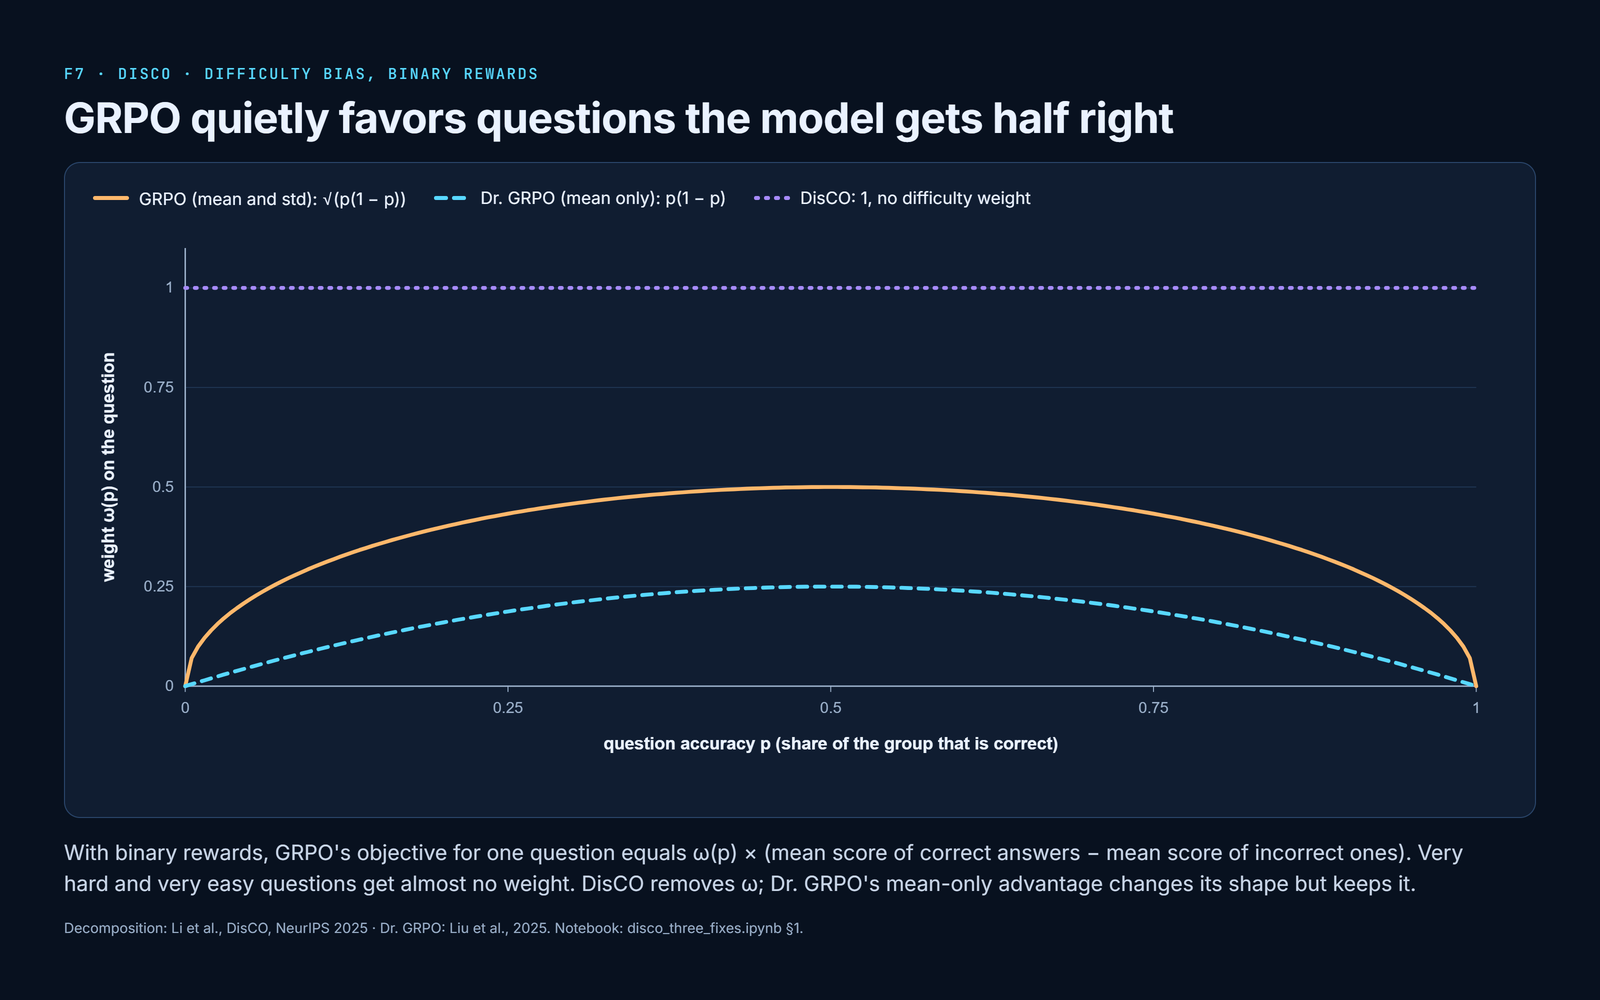

**What you'll observe:** GRPO's implicit weight $\sqrt{p(1-p)}$ starves very hard and very easy questions; without it they learn at the same rate.
*Deck: [difficulty](../slides/disco_intro.html#difficulty), [question weight](../slides/disco_intro.html#question-weight), [discriminative view](../slides/disco_intro.html#discriminative-view).*

$\omega(q)=\sqrt{p(q)(1-p(q))}$ peaks at $p=0.5$ and vanishes at both extremes, so the questions the model almost never gets (and the ones it has almost mastered) barely move the gradient. Fix one is to delete it and train directly on the discriminative term underneath.

**Think first.** Question A is answered correctly half the time, $p=0.5$. Question B is answered correctly once in ten attempts, $p=0.1$. A success on B seems especially informative. Which question does GRPO's normalization actually weight more?

### Predict

Guess $\omega(q)$ at $p\in\{0.01, 0.1, 0.5, 0.9, 0.99\}$, and the ratio $\omega(0.5)/\omega(0.1)$.

In [1]:
# Setup: make grpo_lab importable
import sys, pathlib, subprocess
ROOT = next((p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p / "grpo_lab").exists()), None)
if ROOT is None:   # e.g. opened in Colab: fetch the repository (code, data and figures) first
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/samaksh97/grpo-then-and-now"], check=True)
    ROOT = pathlib.Path("grpo-then-and-now").resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
from grpo_lab import plots

In [2]:
# GRPO's per-question weight omega(q) = sqrt(p(1-p)) versus DisCO's constant weight, at a few difficulties.
import numpy as np

def w_grpo(p):
    return np.sqrt(p * (1 - p))

def w_disco(p):
    """DisCO deletes the weight entirely: every question counts the same."""
    return np.ones_like(np.asarray(p, dtype=float))

ps = [0.01, 0.1, 0.3, 0.5, 0.7, 0.9, 0.99]
print(f"{'p(q)':>6s} {'w_GRPO':>8s} {'w_DisCO':>9s} {'relative to p=0.5':>19s}")
for p in ps:
    print(f"{p:6.2f} {w_grpo(p):8.3f} {float(w_disco(p)):9.3f} {w_grpo(p)/w_grpo(0.5):19.3f}")

print(f"\nw_GRPO(0.5) / w_GRPO(0.1)  = {w_grpo(0.5)/w_grpo(0.1):.2f}x")
print(f"w_GRPO(0.5) / w_GRPO(0.01) = {w_grpo(0.5)/w_grpo(0.01):.2f}x")


  p(q)   w_GRPO   w_DisCO   relative to p=0.5
  0.01    0.099     1.000               0.199
  0.10    0.300     1.000               0.600
  0.30    0.458     1.000               0.917
  0.50    0.500     1.000               1.000
  0.70    0.458     1.000               0.917
  0.90    0.300     1.000               0.600
  0.99    0.099     1.000               0.199

w_GRPO(0.5) / w_GRPO(0.1)  = 1.67x
w_GRPO(0.5) / w_GRPO(0.01) = 5.03x


The middle-difficulty question receives the larger weight: 1.67 times the weight at $p=0.1$, and 5.03 times the weight at $p=0.01$.

### Inspect: is the decomposition actually exact?

The deck's [comparison view](../slides/disco_intro.html#comparison-view) claims an identity, not an approximation. Test it: compute $\mathbb{E}_{o\sim\pi_{\mathrm{old}}}[f(x, A(o|q))]$ the way GRPO actually computes it, and compare against $\omega(q)$ times the discriminative gap.

In [3]:
rng = np.random.default_rng(0)
eps = 0.2
p = 0.3          # this question's difficulty
N = 2_000_000    # Monte Carlo sample size

# Toy per-token ratios x = pi_theta / pi_old for a single-token response,
# drawn differently for positive vs. negative rollouts.
x_pos = np.clip(rng.normal(1.05, 0.3, N), 0.01, None)
x_neg = np.clip(rng.normal(0.95, 0.3, N), 0.01, None)

def f(x, A):
    """GRPO's clipped surrogate f(x, A) = min(xA, clip(x, 1-eps, 1+eps) A)."""
    unclipped = x * A
    clipped = np.clip(x, 1 - eps, 1 + eps) * A
    return np.minimum(unclipped, clipped)

def f_plus(x):  return np.minimum(x, 1 + eps)
def f_minus(x): return np.maximum(x, 1 - eps)

A_pos = np.sqrt((1 - p) / p)          # Eq. 12: advantage when r=1
A_neg = -np.sqrt(p / (1 - p))         # Eq. 12: advantage when r=0

lhs = p * np.mean(f(x_pos, A_pos)) + (1 - p) * np.mean(f(x_neg, A_neg))
rhs = np.sqrt(p * (1 - p)) * (np.mean(f_plus(x_pos)) - np.mean(f_minus(x_neg)))

print(f"LHS:  E_o~old[f(ratio, A(o|q))]        = {lhs:.6f}")
print(f"RHS:  sqrt(p(1-p)) * discriminative gap = {rhs:.6f}")
print(f"match to 1e-3: {np.isclose(lhs, rhs, atol=1e-3)}")


LHS:  E_o~old[f(ratio, A(o|q))]        = -0.008306
RHS:  sqrt(p(1-p)) * discriminative gap = -0.008306
match to 1e-3: True


The two estimates agree up to Monte Carlo noise, which is what we expect from an identity. Next, compare the weight across the full difficulty range with DisCO's constant weight. The vertical scale is arbitrary because a global constant can be absorbed into the learning rate; focus on the *shape* of the curves.

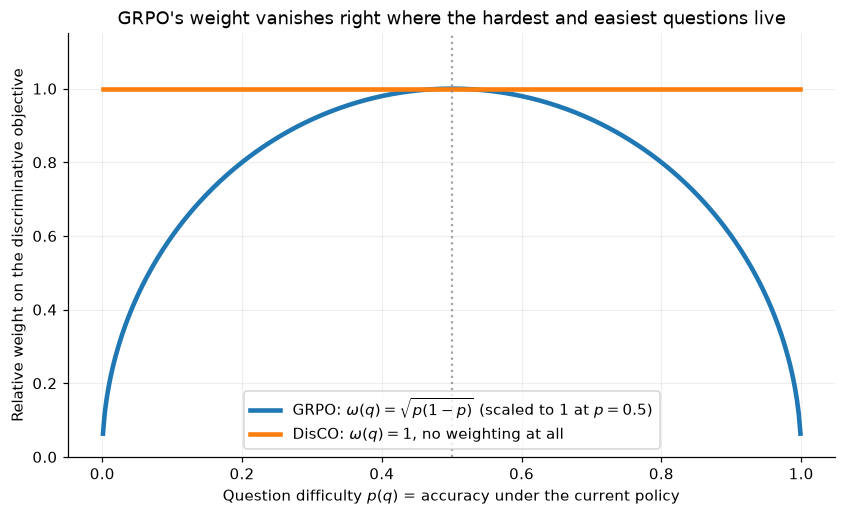

In [4]:
# The two weights across the full difficulty range (GRPO's scaled to 1 at p = 0.5).
p_grid = np.linspace(0.001, 0.999, 400)
plots.disco_weights(p_grid, w_grpo(p_grid) / w_grpo(0.5), w_disco(p_grid))

### Optimize: race three questions

One scalar per question, $z=\mathrm{logit}(p(q))$, nudged by a constant raw push. GRPO scales that push by $\omega(p)$ at the current $p$; DisCO doesn't scale it at all. Note the feedback loop: a question's accuracy feeds straight back into its own next weight.

In [5]:
# Race three questions (hard, medium, easy): each is one logit z = logit(p), pushed by a constant raw
# gradient that GRPO scales by omega(p) at the current p and DisCO leaves unscaled.
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def run_question(p0, weighted, lr=0.05, steps=300):
    """Track one question's accuracy p(t) under a weighted (GRPO) or flat (DisCO) push."""
    z = np.log(p0 / (1 - p0))
    history = []
    for _ in range(steps):
        p = sigmoid(z)
        w = w_grpo(p) if weighted else 1.0
        z += lr * w
        history.append(p)
    return np.array(history)

questions = [(0.02, "hard"), (0.5, "medium"), (0.98, "easy")]
print(f"{'question':>10s} {'weighted p(300)':>16s} {'unweighted p(300)':>18s}")
for p0, label in questions:
    hw = run_question(p0, weighted=True)
    hu = run_question(p0, weighted=False)
    print(f"{label:>10s} {hw[-1]:16.3f} {hu[-1]:18.3f}")


  question  weighted p(300)  unweighted p(300)
      hard            0.644              1.000
    medium            0.983              1.000
      easy            0.995              1.000


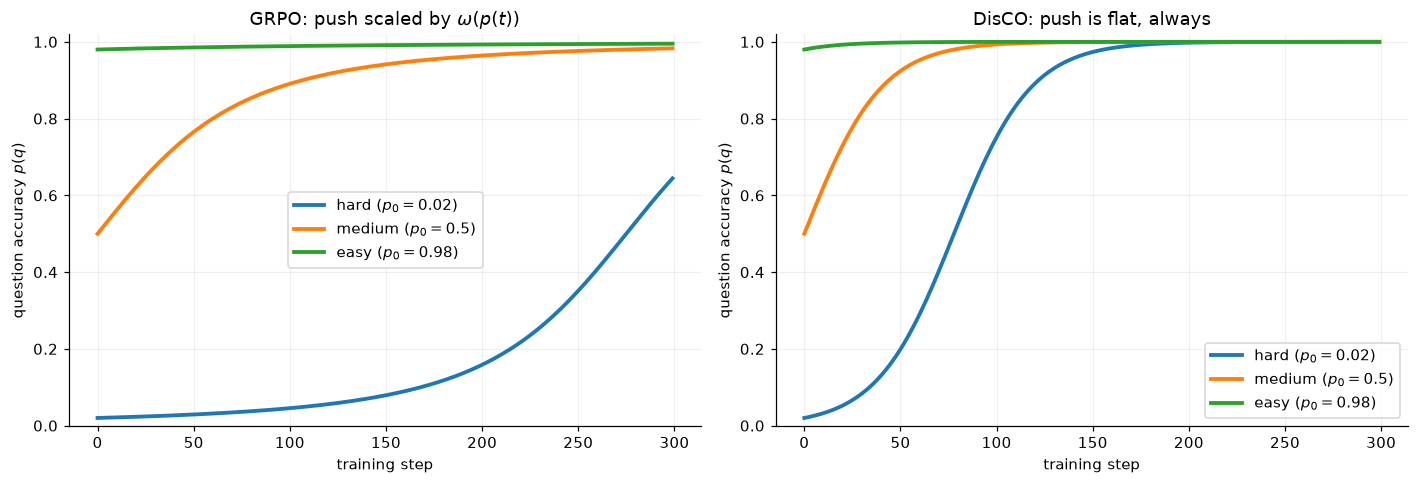

In [6]:
# Accuracy trajectories of the three questions under each weighting.
plots.question_race({label: (p0, run_question(p0, weighted=True), run_question(p0, weighted=False))
                     for p0, label in questions})

The hard question ($p_0=0.02$) stalls at 0.64 under GRPO's weighting and never reaches 90% in 300 steps; unweighted it crosses 90% at step 122 and keeps going. Medium: step 107 vs. step 44. Easy: no real difference, it was already past.

### Explain

Dividing the advantage by $\sqrt{\mathrm{Var}[r]}$ is what puts $\sqrt{p(1-p)}$ in front of the objective, and that factor is smallest exactly where a rare success or a last-mile failure teaches the most. Deleting it leaves a direct discriminative objective, the same idea that drives AUC maximization in ordinary classification. The paper's ablation agrees: dropping $\omega(q)$ alone reaches more fully-mastered and fewer fully-unsolved questions, faster.

**Scope of this fix.** It does not change which questions are sampled, the number of rollouts, or the reward rule. It changes only the contribution of each contrast after the rollouts have been generated.

### Optional exploration (no reference solution)

1. Dr. GRPO drops the square root (it uses the unnormalized advantage $\hat A(o|q)=r(o|q)-p(q)$) but, as the paper shows, still carries the weight $\omega_{\text{Dr.GRPO}}(q)=p(q)(1-p(q))$. Rerun the training race with this weight swapped in for `w_grpo`. Does the hard question ($p_0=0.02$) still stall, and how does its progress compare with full GRPO?
2. The race above uses one scalar difficulty $p(q)$ per question and a constant raw push. Scale it up: 50 questions with $p_0$ drawn from a `Beta(2, 2)` distribution (clustered around the middle) versus `Beta(0.3, 0.3)` (clustered at the extremes). Under which distribution does GRPO's difficulty bias cost you the most total accuracy after a fixed training budget?
3. $\omega(q)$ depends on $p(q)$, but in practice $p(q)$ is estimated from a small group (say $G=8$ or $16$ samples). Simulate $\hat p(q)$ with `rng.binomial(G, p_true)/G` for a hard question ($p=0.02$) and $G=8$, then compute $\omega(\hat p)$ over many groups. How often does sampling noise give the question an unusually large weight? What does this suggest about the bias-variance trade-off of removing $\omega(q)$?

In [7]:
def w_drgrpo_weighted_race(p0, weighted, lr=0.05, steps=300):
    """TODO: mirror run_question, but use w_drgrpo(p) = p*(1-p) instead of w_grpo(p)."""
    z = np.log(p0 / (1 - p0))
    history = []
    for _ in range(steps):
        p = sigmoid(z)
        # TODO: w = w_drgrpo(p) if weighted else 1.0
        w = 1.0
        z += lr * w
        history.append(p)
    return np.array(history)

# Once implemented, compare against run_question(0.02, weighted=True) from above.


---

## 2 · Non-Clipping Scores and a Real Constraint *(about 10 min)*

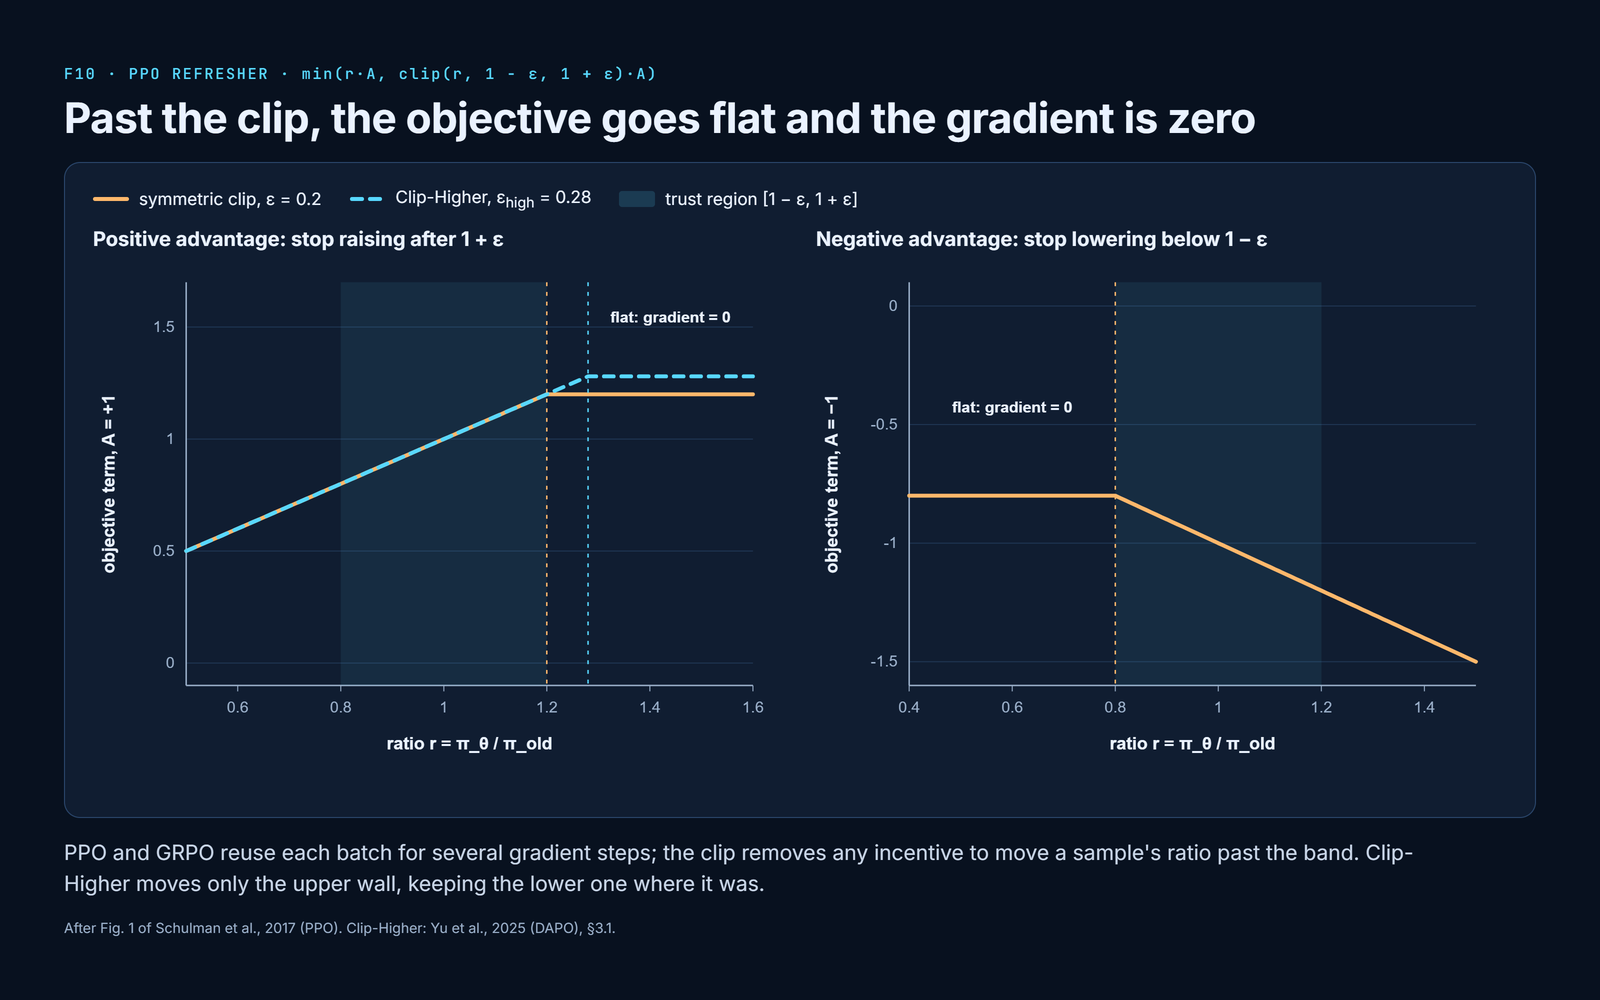

**What you'll observe:** a clipped score has zero gradient past $1+\varepsilon$, a non-clipping score never does, and a squared-hinge constraint pushes back only once the KL crosses $\delta$.
*Deck: [dead gradients](../slides/disco_intro.html#dead-gradients), [two jobs](../slides/disco_intro.html#two-jobs).*

This section separates two jobs. First, the clipped scores $f^+(x,1)=\min(x,1+\varepsilon)$ and $f^-(x,1)=\max(x,1-\varepsilon)$ become one smooth $s_\theta(o,q)$: either log-likelihood, $\frac{1}{|o|}\sum_t\log\pi_\theta(o_t|q,o_{<t})$, or likelihood ratio, $\frac{1}{|o|}\sum_t \pi_\theta/\pi_{\mathrm{old}}$. Second, an explicit trust region handles divergence through a squared hinge instead of an always-on KL penalty:

$$\max_\theta\ \mathcal{J}_1(\theta)\ \ \text{s.t.}\ \ \mathbb{D}_{\mathrm{KL}}(\pi_{\mathrm{old}}\|\pi_\theta)\le\delta \qquad\Longrightarrow\qquad \max_\theta\ \mathcal{J}_1(\theta) - \beta\big[\mathbb{D}_{\mathrm{KL}}(\pi_{\mathrm{old}}\|\pi_\theta)-\delta\big]_+^2.$$

**Think first.** A token's ratio has drifted to $x=1.5$, past the clip window. What gradient does it get? And separately: does a plain KL regularizer ever stop pulling, even when the policy is nowhere near the limit?

### Predict

Guess $d(\text{score})/dx$ at $x\in\{0.5, 1.0, 1.2, 1.5, 2.0\}$ for GRPO's clipped L-ratio ($\varepsilon=0.2$), DisCO's plain L-ratio, and DisCO's log-L (whose derivative in $x$ is $1/x$).

In [8]:
# Gradient of each score with respect to the ratio x for a positive-advantage token:
# GRPO's clipped score drops to 0 past 1 + eps; DisCO's likelihood-ratio and log-likelihood scores never do.
eps = 0.2

for xv in [0.5, 0.9, 1.0, 1.1, 1.2, 1.5, 2.0]:
    g_clip = 1.0 if xv < 1 + eps else 0.0
    print(f"x={xv:4.2f}  GRPO-clipped grad={g_clip:.2f}  L-ratio grad=1.00  log-L grad={1/xv:.2f}")


x=0.50  GRPO-clipped grad=1.00  L-ratio grad=1.00  log-L grad=2.00
x=0.90  GRPO-clipped grad=1.00  L-ratio grad=1.00  log-L grad=1.11
x=1.00  GRPO-clipped grad=1.00  L-ratio grad=1.00  log-L grad=1.00
x=1.10  GRPO-clipped grad=1.00  L-ratio grad=1.00  log-L grad=0.91
x=1.20  GRPO-clipped grad=0.00  L-ratio grad=1.00  log-L grad=0.83
x=1.50  GRPO-clipped grad=0.00  L-ratio grad=1.00  log-L grad=0.67
x=2.00  GRPO-clipped grad=0.00  L-ratio grad=1.00  log-L grad=0.50


Past $x=1.2$, the clipped derivative is zero: that token contributes no gradient to this update. The L-ratio keeps slope 1, while log-L tapers smoothly—steeper for low-probability tokens and gentler for likely ones—without becoming flat.

### Inspect: three gradients side by side

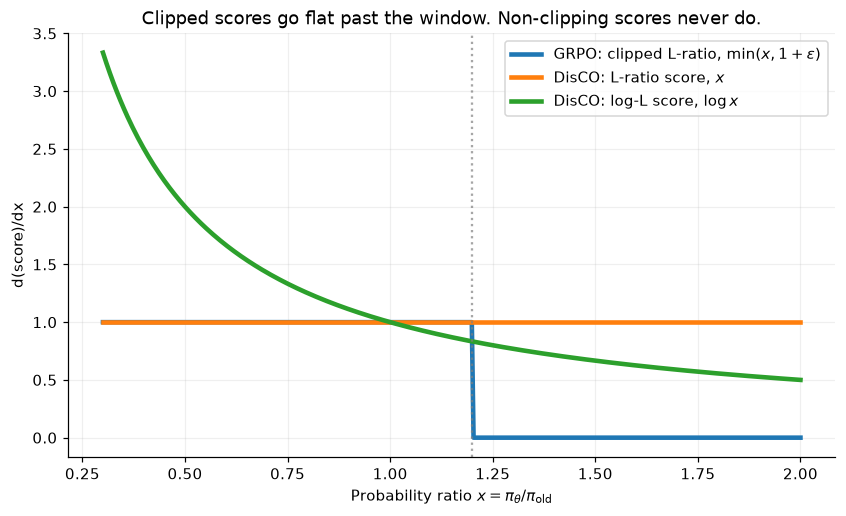

In [9]:
# Plot the three gradients from the previous cell over a range of ratios.
x = np.linspace(0.3, 2.0, 400)

def grpo_clipped_grad(x, eps=eps):
    return np.where(x < 1 + eps, 1.0, 0.0)

plots.score_gradients(x, grpo_clipped_grad(x), eps)

Same diagnosis as `dapo_four_fixes.ipynb`, different prescription: DAPO widens the window to $\varepsilon_{\mathrm{high}}=0.28$, which moves the wall; DisCO removes it and hands divergence control to a separate mechanism.

### Optimize: a constraint vs. a tax

Toy divergence $z$ with $\mathrm{KL}\approx z^2/2$ and a constant push $g=1$ (a non-clipping score never saturates, so the push never fades on its own):

- **KL regularization**, always on: $\dot z = g - \lambda z$
- **Squared hinge**, DisCO: $\dot z = g - 2\beta[z^2/2-\delta]_+ z$

Trust region $\delta=1$ in toy units (the paper uses $\delta=10^{-4}$, $\beta=10^3$, so that $\beta\delta\approx0.1$ once violated), with $\lambda$ chosen so both would settle at the same asymptote $\sqrt{2\delta}$.

In [10]:
# A 1-D model of policy drift z under a constant raw push g (KL ~ z^2 / 2). The always-on KL penalty
# pulls back with force lam * z at every step; lam is chosen so it settles exactly at KL = delta.
# The squared-hinge constraint pulls back only once KL exceeds delta (DisCO's trust region).
g, delta, beta = 1.0, 1.0, 5.0
lam = g / np.sqrt(2 * delta)
dt, T = 0.01, 400

z_reg, z_con = 0.0, 0.0
hist_reg, hist_con = [], []
for _ in range(T):
    hist_reg.append(z_reg)
    hist_con.append(z_con)
    dz_reg = g - lam * z_reg
    dz_con = g - 2 * beta * max(z_con**2 / 2 - delta, 0.0) * z_con
    z_reg += dt * dz_reg
    z_con += dt * dz_con
hist_reg, hist_con = np.array(hist_reg), np.array(hist_con)
kl_reg, kl_con = hist_reg**2 / 2, hist_con**2 / 2

print(f"lambda (regularization coefficient, matched asymptote) = {lam:.4f}\n")
print(f"{'t':>4s} {'z_reg':>7s} {'KL_reg':>8s} {'z_con':>7s} {'KL_con':>8s}")
for t in [0, 50, 100, 150, 200, 300, 399]:
    print(f"{t:4d} {hist_reg[t]:7.3f} {kl_reg[t]:8.4f} {hist_con[t]:7.3f} {kl_con[t]:8.4f}")


lambda (regularization coefficient, matched asymptote) = 0.7071

   t   z_reg   KL_reg   z_con   KL_con
   0   0.000   0.0000   0.000   0.0000
  50   0.422   0.0892   0.500   0.1250
 100   0.719   0.2582   1.000   0.5000
 150   0.926   0.4291   1.456   1.0597
 200   1.072   0.5747   1.462   1.0684
 300   1.246   0.7762   1.462   1.0684
 399   1.331   0.8856   1.462   1.0684


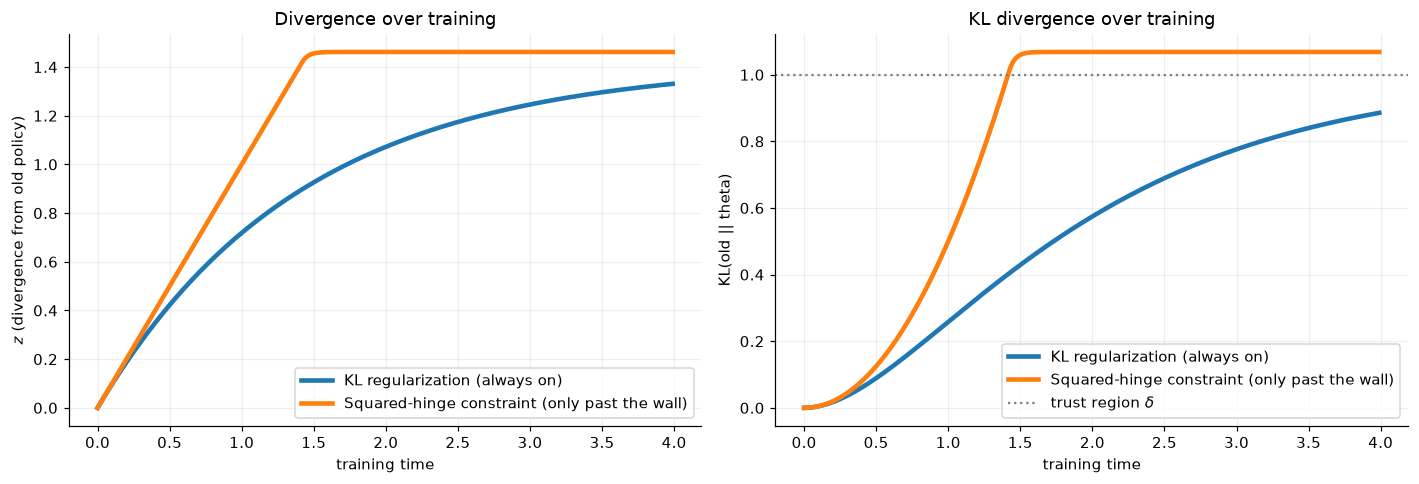

In [11]:
# Divergence and KL over time for the always-on penalty and the squared-hinge constraint.
plots.kl_penalty_vs_constraint(np.arange(T) * dt, hist_reg, hist_con, delta)

The constrained run reaches equilibrium by about $t\approx1.5$ ($z\approx1.46$, just beyond the boundary, where the restoring force balances the update). The regularized run is still approaching the same point at $t=4$ because $\lambda z$ acts from the beginning, even while $z$ is well inside the trust region.

### Explain

$\beta\nabla\mathbb{D}_{\mathrm{KL}}$ is paid at every step regardless of need. The squared hinge's gradient, $2\beta[\mathbb{D}_{\mathrm{KL}}-\delta]_+\nabla\mathbb{D}_{\mathrm{KL}}$, is exactly zero while the constraint holds and only switches on at the boundary. Two problems, two mechanisms: smooth scores kill the token-level saturation behind entropy collapse, the constraint removes the policy-level drag. The paper's ablations back both independently, and call the non-clipping score "of vital importance."

**Scope of this fix.** Divergence is still controlled. The difference is that the control term is inactive inside the permitted region and responds only after the boundary is crossed.

### Optional exploration (no reference solution)

1. Rerun the toy race with $\delta=0.01$, a much tighter trust region, closer to the paper's actual $\delta=10^{-4}$, and retune $\lambda$ to match the new asymptote $\sqrt{2\delta}$. Does the gap between the two trajectories' time to equilibrium grow or shrink as $\delta$ tightens?
2. Add a second, larger raw push, $g=3$, competing against the same constraint. For the squared hinge case, does the trajectory overshoot $\delta$ before settling, and if it does, does a bigger $\beta$ shrink the overshoot without slowing down the climb before the wall?
3. The `grpo_clipped_grad` plot only shows the positive advantage half of GRPO's clip, $f^+$. Implement `f_minus_grad(x, eps)` for $f^-(x,1)=\max(x,1-\varepsilon)$ and add its derivative to the plot. Where does its flat region sit, and why does it land on the opposite side of $x=1$ from $f^+$'s?

In [12]:
def f_minus_grad(x, eps=0.2):
    """TODO: derivative of f^-(x, 1) = max(x, 1 - eps) with respect to x."""
    # Hint: max(x, 1-eps) equals x when x > 1-eps, and the constant 1-eps otherwise.
    return np.ones_like(x)

# Once implemented, overlay f_minus_grad(x) on the plot above and compare
# its flat region to grpo_clipped_grad(x)'s.


---

## 3 · When 99 Easy Negatives Hide the One That Matters *(about 10 min)*

![DisCO's hard-negative weighting: the softmax weight on one high-scoring confuser among 100 negatives rises from 1% to 98.8% as the temperature falls to 0.1; with that weighting the confuser's score drops from 0.900 to 0.321 in 80 steps, compared with 0.898 under a plain average.](attachment:F11_disco_hard_negatives.png)

**What you'll observe:** under a plain average one high-scoring wrong answer hides behind 99 easy ones; a softmax over negatives puts almost all the gradient on it.
*Deck: [KL constraint](../slides/disco_intro.html#kl-constraint), [sparse rewards](../slides/disco_intro.html#sparse-rewards).*

$\mathcal{J}_1$ averages the score gap uniformly over negatives. Fix three replaces that average with a softmax-weighted one at temperature $\tau$:

$$\mathcal{J}_2(\theta) = -\mathbb{E}_q\,\mathbb{E}_{o^+}\left[\tau\log\Big(\mathbb{E}_{o^-}\exp\Big(\tfrac{s_\theta(o',q)-s_\theta(o,q)}{\tau}\Big)\Big)\right].$$

$\tau\to\infty$ recovers the plain average; $\tau\to0$ gives $s_\theta(o^+,q)-\max_{o'}s_\theta(o',q)$, the single hardest negative and nothing else.

**Think first.** One positive scored $0.5$; 99 negatives at $0.001$; one **confuser** at $0.9$, above the positive. Pairwise AUC is $99/100=0.99$. Does that number mean the question is solved?

### Predict

Guess $\mathcal{J}_1 = s_{\mathrm{pos}}-\overline{s_{\mathrm{neg}}}$, the AUC, and how the confuser's share of the gradient moves as $\tau$ sweeps from 20 down to 0.01.
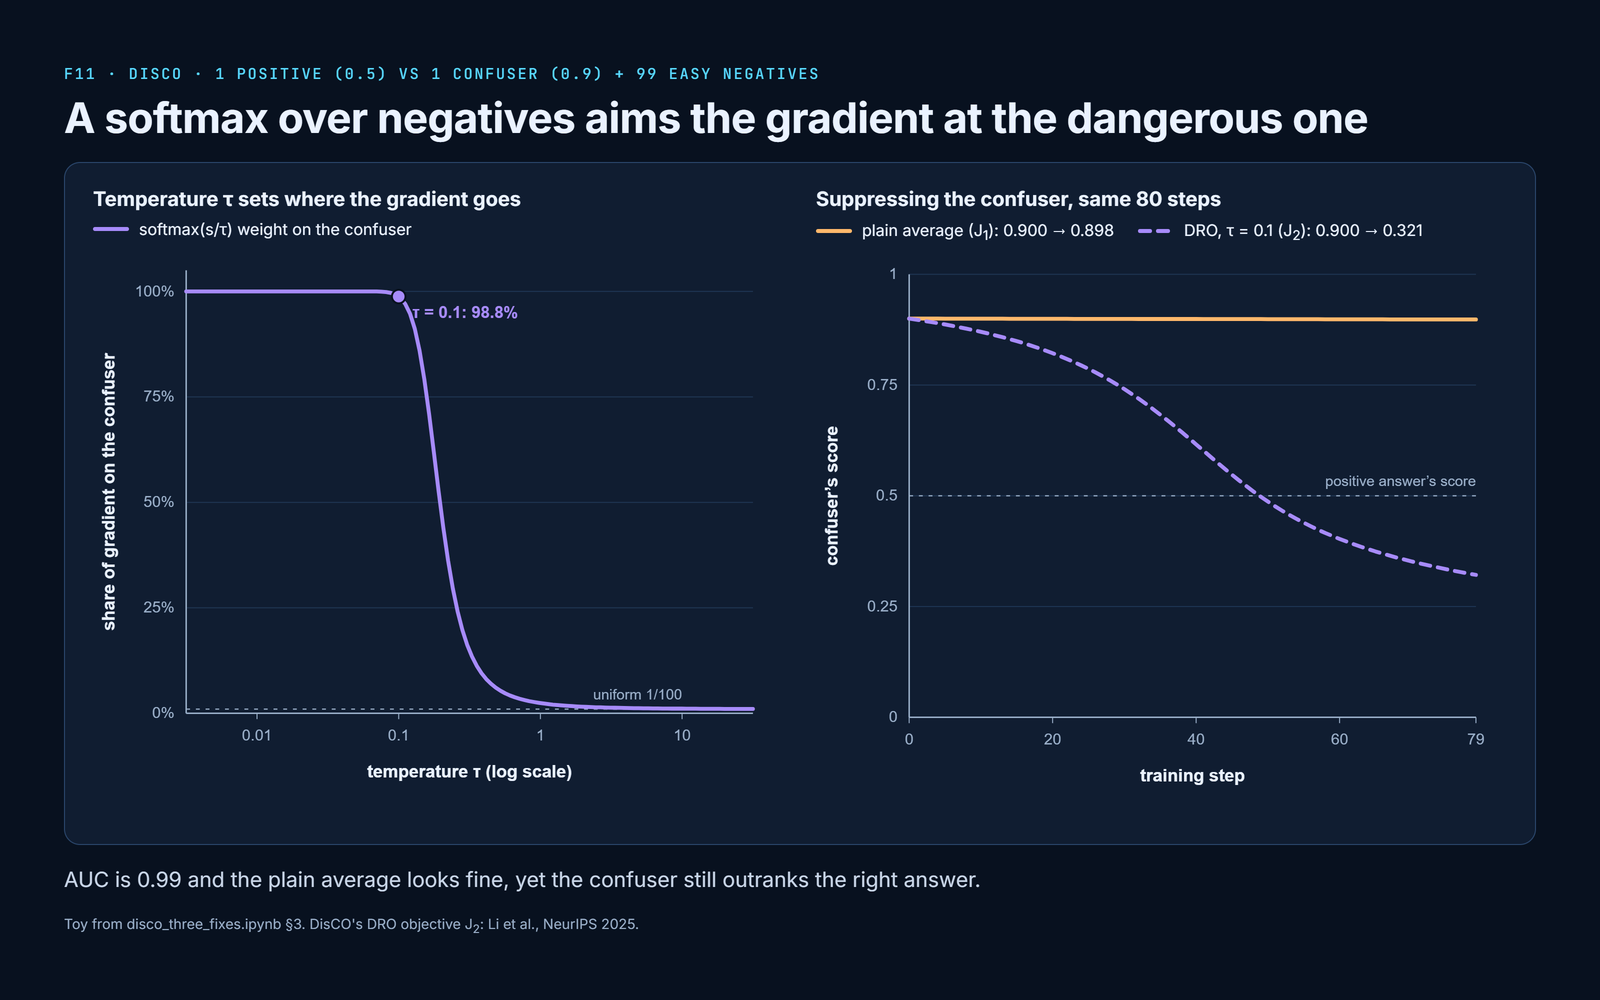

In [13]:
# One positive (score 0.5) against 100 negatives: one 'confuser' scored 0.9 above it and 99 easy ones.
# J1 (plain average gap) and AUC both look fine; the DRO objective J2 at temperature tau does not.
import numpy as np

s_pos, s_conf, s_easy, n_easy = 0.5, 0.9, 0.001, 99
negs = np.array([s_conf] + [s_easy] * n_easy)

J1 = s_pos - negs.mean()
auc = np.mean(s_pos > negs)
print(f"J1 (plain average score gap) = {J1:.4f}")
print(f"AUC (fraction of negatives correctly ranked below the positive) = {auc:.4f}")

def J2(tau):
    return -tau * np.log(np.mean(np.exp((negs - s_pos) / tau)))

def weight_on_confuser(tau):
    w = np.exp(negs / tau)
    return (w / w.sum())[0]

print(f"\n{'tau':>6s} {'J2':>8s} {'weight on confuser':>20s}")
for tau in [20, 10, 5, 1, 0.5, 0.1, 0.05, 0.01]:
    print(f"{tau:6.2f} {J2(tau):8.4f} {weight_on_confuser(tau):20.4f}")

print(f"\nlimit as tau->inf: weight_on_confuser -> 1/{n_easy+1} = {1/(n_easy+1):.4f}  (uniform, recovers J1)")
print(f"limit as tau->0:   J2 -> s_pos - max(negs) = {s_pos - negs.max():.4f}  (focuses on the confuser alone)")


J1 (plain average score gap) = 0.4900
AUC (fraction of negatives correctly ranked below the positive) = 0.9900

   tau       J2   weight on confuser
 20.00   0.4898               0.0105
 10.00   0.4896               0.0109
  5.00   0.4892               0.0119
  1.00   0.4845               0.0242
  0.50   0.4744               0.0575
  0.10   0.0593               0.9878
  0.05  -0.1697               1.0000
  0.01  -0.3539               1.0000

limit as tau->inf: weight_on_confuser -> 1/100 = 0.0100  (uniform, recovers J1)
limit as tau->0:   J2 -> s_pos - max(negs) = -0.4000  (focuses on the confuser alone)


$\mathcal{J}_1=0.49$ and $\mathrm{AUC}=0.99$ both look finished, while the model still ranks the confuser above the right answer: 99 negatives that were never in doubt swamp the one that is. At $\tau=20$ the confuser holds $0.0105$ of the gradient (essentially the uniform $1/100$); at $\tau=0.1$ it holds $0.988$, and $\mathcal{J}_2$ drops to $0.06$, finally reporting the problem. At $\tau\to0$, $\mathcal{J}_2\to0.5-0.9=-0.4$.

### Inspect: watch the handoff

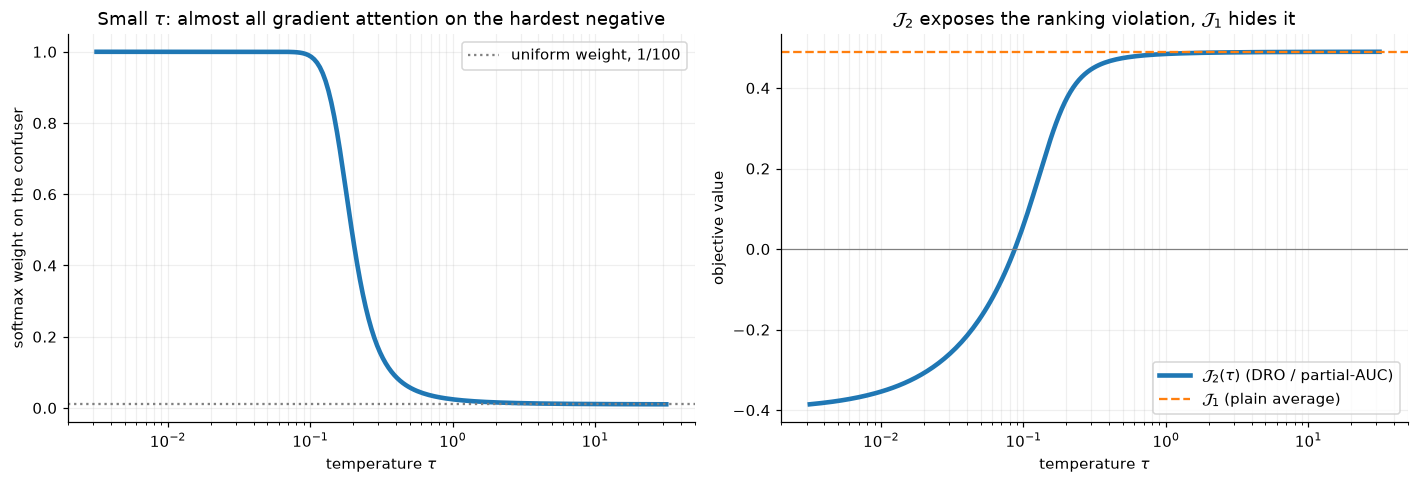

In [14]:
# How the temperature tau sets the softmax weight on the confuser, and the resulting value of J2.
tau_grid = np.logspace(-2.5, 1.5, 200)
plots.dro_temperature(tau_grid, [weight_on_confuser(t) for t in tau_grid], [J2(t) for t in tau_grid],
                      J1, n_negatives=n_easy + 1)

### Optimize: does chasing the confuser fix it faster?

Freeze the 99 easy negatives, run gradient ascent on the confuser's own score: first under $\mathcal{J}_1$ (uniform $1/100$ share), then under $\mathcal{J}_2$ at $\tau=0.1$.

In [15]:
# Train only the confuser's score down, with its gradient weighted uniformly (J1) or by the DRO
# softmax at tau = 0.1 (J2). Which suppresses the dangerous negative faster?
def sigmoid(z): return 1 / (1 + np.exp(-z))
def logit(p): return np.log(p / (1 - p))

def suppress_confuser(tau_or_none, lr=0.3, epochs=80):
    """tau_or_none=None means the plain average (J1); else the DRO objective at that tau."""
    z_conf = logit(0.9)
    history = []
    for _ in range(epochs):
        p_conf = sigmoid(z_conf)
        scores = np.concatenate([[p_conf], np.full(n_easy, s_easy)])
        if tau_or_none is None:
            w = 1.0 / (n_easy + 1)          # uniform weight, same as any other negative
        else:
            sm = np.exp(scores / tau_or_none)
            w = (sm / sm.sum())[0]
        grad = -w * p_conf * (1 - p_conf)   # push the confuser's own score down, scaled by its weight
        z_conf += lr * grad
        history.append(p_conf)
    return history

h_j1 = suppress_confuser(None)
h_j2 = suppress_confuser(0.1)
print(f"Confuser's score after {len(h_j1)} steps under J1 (uniform weight): {h_j1[-1]:.4f}")
print(f"Confuser's score after {len(h_j2)} steps under J2 (tau=0.1):        {h_j2[-1]:.4f}")


Confuser's score after 80 steps under J1 (uniform weight): 0.8980
Confuser's score after 80 steps under J2 (tau=0.1):        0.3215


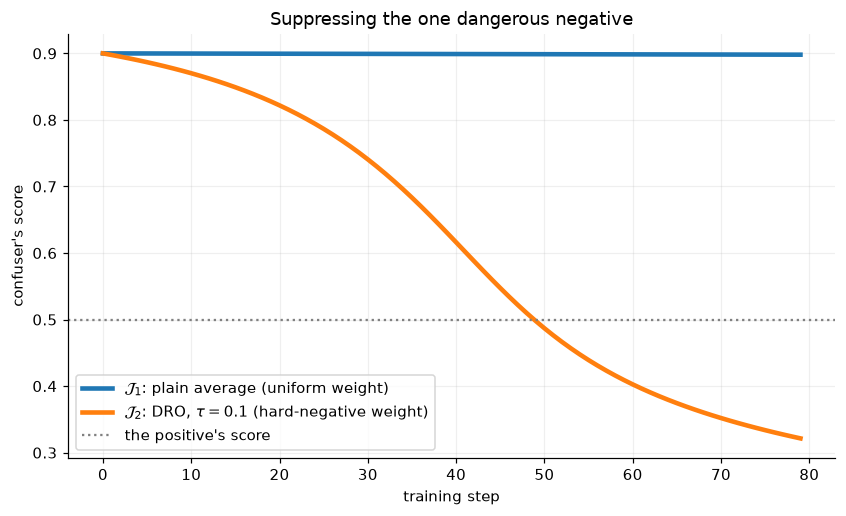

In [16]:
# The confuser's score over training under J1 and J2.
plots.confuser_suppression(h_j1, h_j2, s_pos)

Under $\mathcal{J}_1$ the confuser moves from $0.900$ to $0.898$ in 80 steps, diluted to the same $1/100$ as negatives that were never a threat. Under $\mathcal{J}_2$ it falls to $0.32$, below the positive, in the same 80 steps.

### Explain

$\mathcal{J}_2$ is the closed form of a distributionally-robust take on *partial* AUC: it reweights each negative by $\mathrm{softmax}(s_\theta(o',q)/\tau)$, aiming the gradient at whichever negatives currently look most like the answer. Jensen's inequality gives $\mathcal{J}_2\le\mathcal{J}_1$, so raising $\mathcal{J}_2$ raises $\mathcal{J}_1$ too, but not the reverse; that asymmetry is why full DisCO beats the plain-average DisCO-b, most visibly on AIME where imbalance is worst. Practical note: $\tau$ must match the score's scale ($\tau=1$ for L-ratio, $\tau=10$ for log-L), though performance barely moves across $\tau\in\{0.5,1,5,10\}$.

**Scope of this fix.** It leaves the reward, score function, and difficulty weight unchanged. It changes only how the negative rollouts for one question are combined.

### Optional exploration (no reference solution)

1. Sweep the number of easy negatives, $n_{\text{easy}}\in\{10, 50, 99, 500\}$, holding the confuser fixed at $0.9$ and the positive at $0.5$, and plot the softmax weight on the confuser at a fixed $\tau=0.1$. Does the plain average $\mathcal{J}_1$ keep getting worse as $n_{\text{easy}}$ grows, even though the confuser's own score never moves?
2. Add a second confuser, scored $0.6$ (also above the positive, but less dangerous than the $0.9$ one). At $\tau=0.1$, does the DRO objective split its attention evenly between the two, or does it concentrate on the more dangerous one? What changes if $\tau$ goes up to $1$?
3. Implement the $\tau\to0$ limit directly (`s_pos - negs.max()`) as a `hardest_negative_objective`, and compare its gradient behavior on the two confuser scenario from (2) against $\mathcal{J}_2$ at a small but nonzero $\tau$. What does the hard max lose that the soft, temperature controlled version keeps?

In [17]:
def softmax_weights(scores, tau):
    """TODO: return the normalized softmax weights exp(scores/tau) / sum(...)."""
    return np.full_like(scores, 1.0 / len(scores))

# Once implemented:
# for n_easy_sweep in [10, 50, 99, 500]:
#     negs_sweep = np.array([s_conf] + [s_easy]*n_easy_sweep)
#     print(n_easy_sweep, softmax_weights(negs_sweep, tau=0.1)[0])


---

## 4 · Putting It Together: One DisCO Loop *(about 10 min)*

**What you'll observe:** on the hard question DisCO reaches 90% accuracy in about a third of the GRPO-style control's steps, with its per-step KL inside the trust region.
*Deck: [hard negatives](../slides/disco_intro.html#hard-negatives).*

We have examined the three fixes separately. We will now combine them in a deliberately small model so that every part of the update remains visible.

**The model.** Each question has $K=6$ candidate answers. Index 0 is correct, index 1 is a plausible confuser holding most of the wrong-answer probability, and the rest are clearly wrong fillers. The policy is a softmax over logits $\theta$, so a "rollout" is one sampled answer and its log-likelihood score is $\log\pi_\theta(o)$. The gradients are analytic: $\nabla_\theta\log\pi_\theta(o)=\mathbb{1}[o]-\pi_\theta$ and $\nabla_\theta\mathbb{D}_{\mathrm{KL}}(\pi_{\mathrm{old}}\|\pi_\theta)=\pi_\theta-\pi_{\mathrm{old}}$.

Each step samples a group of $G=16$ rollouts from $\pi_{\mathrm{old}}$, splits them by the verifier, and takes a few inner updates before refreshing $\pi_{\mathrm{old}}$ — the same shape as the real loop, minus the transformer.

To isolate the effects, both update rules use the same sampling loop and the same divergence control:

| | negatives combined by | question weight | divergence control |
|---|---|---|---|
| `grpo_grad` | plain average | $\omega(\hat p)=\sqrt{\hat p(1-\hat p)}$ | squared hinge (kept identical, so it isn't the variable) |
| `disco_grad` | softmax at $\tau$ | none | squared hinge |

### Predict

Three questions start at $p_0\in\{0.02, 0.5, 0.9\}$. Guess how many steps each needs to reach 90% accuracy under the two updates, and whether the KL constraint is ever violated.

In [18]:
# A complete small DisCO loop on one question with K = 6 possible answers: index 0 is correct,
# index 1 a plausible confuser, the rest filler. The small helpers live in grpo_lab/disco.py.
from grpo_lab.disco import K, CORRECT, CONFUSER, init_logits, grad_logp, split, kl_old_new
from grpo_lab.objectives import softmax

def disco_grad(theta, rollouts, tau):
    """Fix 1 (no omega) + fix 3 (softmax over negatives), on the log-L score."""
    probs = softmax(theta)
    logp = np.log(probs)
    pos, neg = split(rollouts)
    if len(pos) == 0 or len(neg) == 0:
        return np.zeros_like(theta)              # unanimous group: nothing to contrast
    w = softmax(logp[neg] / tau)                 # DRO weights; uniform as tau -> inf
    g = sum(grad_logp(probs, o) for o in pos) / len(pos)
    for o, wi in zip(neg, w):
        g -= wi * grad_logp(probs, o)
    return g

In [19]:
# The control: GRPO's omega-weighted gradient with negatives averaged uniformly.
def grpo_grad(theta, rollouts):
    """The control: same score, but omega-weighted and averaging negatives uniformly."""
    probs = softmax(theta)
    pos, neg = split(rollouts)
    if len(pos) == 0 or len(neg) == 0:
        return np.zeros_like(theta)
    p_hat = len(pos) / len(rollouts)
    g = (sum(grad_logp(probs, o) for o in pos) / len(pos)
         - sum(grad_logp(probs, o) for o in neg) / len(neg))
    return np.sqrt(p_hat * (1 - p_hat)) * g

In [20]:
from grpo_lab.disco import train, steps_to   # outer loop with the squared-hinge trust region

grads = {"grpo": grpo_grad, "disco": lambda theta, rollouts: disco_grad(theta, rollouts, tau=0.1)}
questions = {"hard": (0.02, 0.60), "medium": (0.50, 0.30), "easy": (0.90, 0.06)}
runs = {}
print(f"{'question':>9s} {'steps to 90%':>22s} {'final accuracy':>20s} {'max KL / step':>20s}")
print(f"{'':9s} {'GRPO-style':>10s} {'DisCO':>11s} {'GRPO-style':>10s} {'DisCO':>9s} {'GRPO-style':>12s} {'DisCO':>7s}")
for label, (p0, p_conf) in questions.items():
    runs[label] = {kind: train(fn, p0, p_conf) for kind, fn in grads.items()}
    (ag, kg, cg), (ad, kd, cd) = runs[label]["grpo"], runs[label]["disco"]
    print(f"{label:>9s} {str(steps_to(ag)):>10s} {str(steps_to(ad)):>11s} "
          f"{ag[-1]:10.3f} {ad[-1]:9.3f} {kg.max():12.4f} {kd.max():7.4f}")
print("\ntrust region delta = 0.0100")


 question           steps to 90%       final accuracy        max KL / step
          GRPO-style       DisCO GRPO-style     DisCO   GRPO-style   DisCO
     hard         98          32      0.984     0.998       0.0023  0.0073
   medium         19           7      0.992     0.998       0.0026  0.0148
     easy          0           0      0.994     0.998       0.0007  0.0046

trust region delta = 0.0100


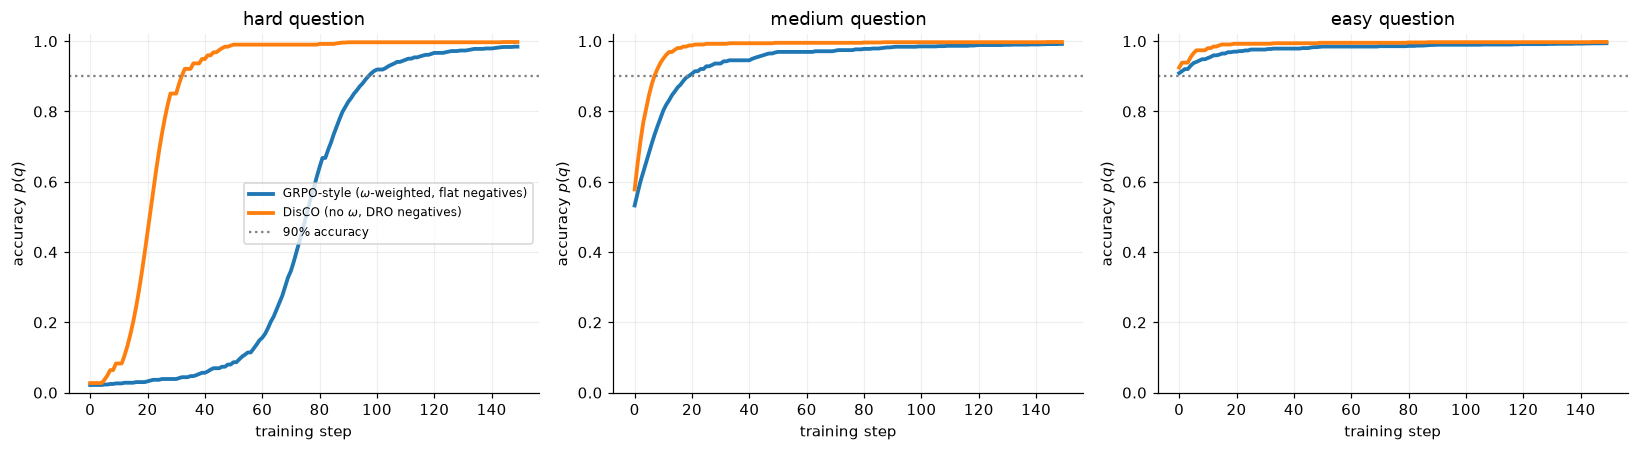

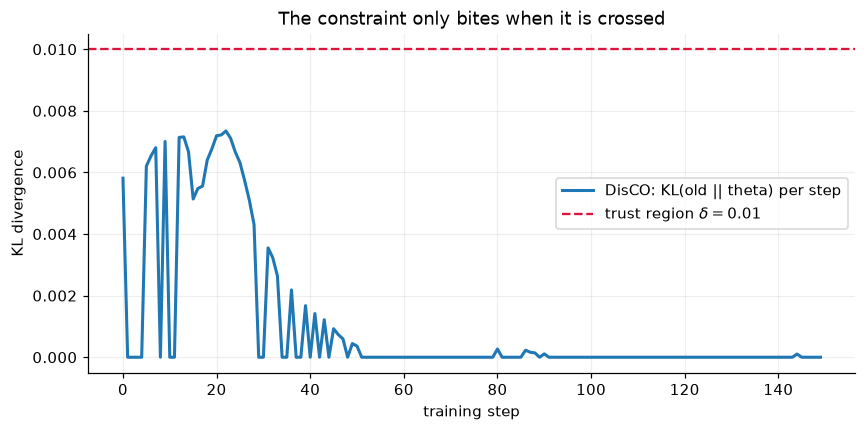

In [21]:
# Accuracy per question (GRPO-style control vs DisCO), then DisCO's per-step KL on the hard question.
plots.disco_training(runs)

### Explain

All three fixes show up at once, in one loop:

- **Fix 1 in the left panel.** The hard question reaches 90% at step 32 under DisCO versus step 98 under $\omega$-weighting — the same 3x gap section 1 predicted from the weight curve alone, now with sampling noise, a real softmax policy, and a KL constraint in the way. The easy question is past 90% from the start, so it separates the least; the bias bites hardest exactly where the weight is smallest.
- **Fix 2 in the KL trace.** Per-step KL sits well under $\delta=0.01$ for most of training and gets pulled back whenever it crosses; nothing drags on the update while the policy is inside the region. Try setting `beta=0` and watch the trace walk away.
- **Fix 3 in the confuser.** Because $\tau=0.1$ concentrates the negative-side gradient on the highest-scoring wrong answer, the confuser is suppressed first, which is what frees up probability mass for the correct answer. At large $\tau$ the same loop spreads that budget over five wrong answers, four of which were never plausible.

Keep the limits of this example in view: a 6-way softmax has no token sequence, length effects, or reward hacking. It demonstrates the *shape* of each fix, not the effect sizes reported in the paper. It does, however, reproduce the unanimous-group failure: once every sampled rollout is correct, the negative pile is empty and the discriminative gradient is zero. DAPO addresses that separate problem with dynamic sampling (see [`dapo_four_fixes.ipynb`](dapo_four_fixes.ipynb)); DisCO inherits it.

### Optional exploration (no reference solution)

1. Set `beta=0` (no constraint at all) and `inner=8`. How far does KL drift per step, and does accuracy actually improve faster, or does the policy thrash?
2. Sweep `tau` over $\{0.05, 0.1, 1, 10\}$ for the hard question and track the confuser's probability rather than accuracy. Where does the confuser stop being suppressed preferentially?
3. Count the fraction of steps whose group was unanimous (no positives, or no negatives) for each question, and plot it against training step. Which question wastes the most compute, and at what stage of training?
4. Replace the log-L score with the L-ratio score, $s_\theta(o)=\pi_\theta(o)/\pi_{\mathrm{old}}(o)$, whose gradient is $\frac{\pi_\theta(o)}{\pi_{\mathrm{old}}(o)}\big(\mathbb{1}[o]-\pi_\theta\big)$. Does $\tau=0.1$ still behave, or does it need rescaling to match the new score's range?

In [22]:
def unanimous_fraction(kind, p0, p_conf, steps=150, G=16, seed=0):
    """TODO: rerun the loop and return the fraction of steps where the group had
    no positives or no negatives (i.e. disco_grad/grpo_grad returned exactly zero)."""
    rng = np.random.default_rng(seed)
    theta = init_logits(p0, p_conf)
    dead = 0
    for _ in range(steps):
        p_old = softmax(theta)
        rollouts = rng.choice(K, size=G, p=p_old)
        # TODO: pos, neg = split(rollouts); if either is empty, dead += 1
        # (then reuse the update body from train() so the policy keeps moving)
        pass
    return dead / steps


---

## Summary

![Reported results: average Pass@1 over six math benchmarks for GRPO versus the best DisCO variant (1.5B: 0.457 vs 0.533; 7B: 0.592 vs 0.627; Llama 8B: 0.516 vs 0.584), and S-GRPO's 40.4 to 61.1% shorter reasoning with an accuracy change of +0.72 to +3.92 points.](attachment:F14b_disco_and_s_grpo_results.png)

| # | Fix | What changes | Problem it solves | Deck | Notebook |
|---|---|---|---|---|---|
| 1 | Discriminative objective | Drop $\omega(q)=\sqrt{p(q)(1-p(q))}$ | Difficulty bias | [question weight](../slides/disco_intro.html#question-weight) | §1 |
| 2 | Non-clipping scores + constrained optimization | Smooth log-L or L-ratio score; squared-hinge KL trust region | Entropy instability, and a regularizer that never turns off | [dead gradients](../slides/disco_intro.html#dead-gradients) | §2 |
| 3 | Partial AUC via DRO | Softmax-weighted average over negatives | Imbalanced rollouts | [hard negatives](../slides/disco_intro.html#hard-negatives) | §3 |

All three together is **DisCO**; fixes 1 and 2 with a plain average for 3 is **DisCO-b**, which the paper reports as clearly weaker, especially on AIME.

## Reference

Li, Lin, Galanti, Tu, and Yang (2025), [DisCO: Reinforcing Large Reasoning Models with Discriminative Constrained Optimization](https://arxiv.org/abs/2505.12366) (NeurIPS 2025). Equation and table numbers refer to that paper. Code: [github.com/optimization-ai/DisCO](https://github.com/optimization-ai/DisCO).

Slides: [`slides/disco_intro.html`](../slides/disco_intro.html). Companion notebook on a different set of fixes to the same GRPO objective: [`dapo_four_fixes.ipynb`](dapo_four_fixes.ipynb), on Yu et al. (2025), [DAPO](https://arxiv.org/abs/2503.14476).
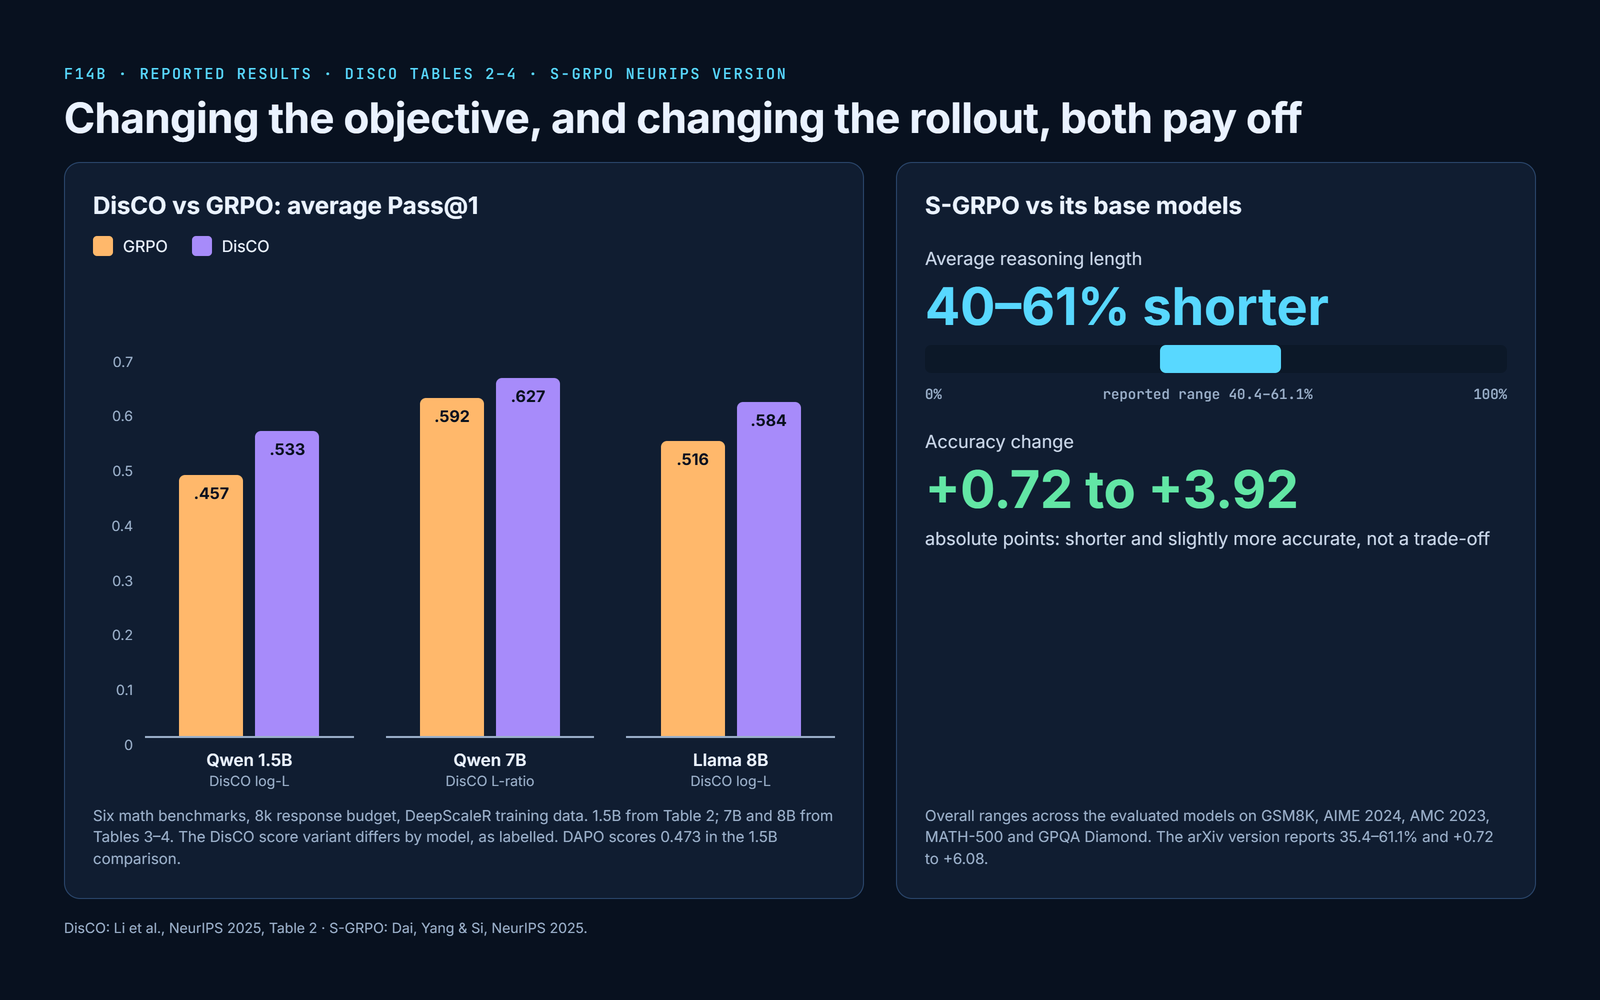